# Activation Functions

1. Step Function
2. Sigmoid
3. Tanh
4. ReLU
5. Leaky ReLU
6. Softmax

## Step Function

$$
f(x) =
\begin{cases}
1 \quad \text{if} x \geq \theta \\
0 \quad \text{otherwise}
\end{cases}
$$

- not used in practice

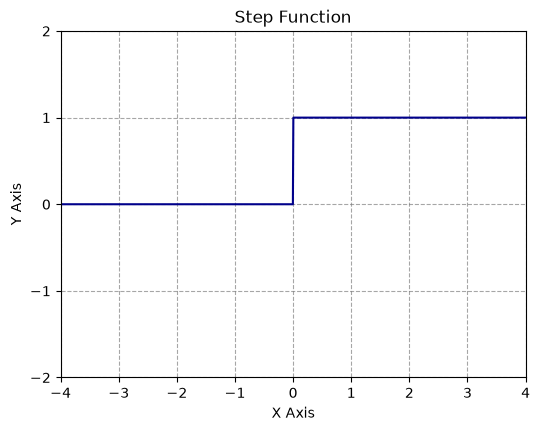

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)
y = np.heaviside(x, 1)          # 0 for x < 0, 1 for x >= 0

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, y, color="darkblue", linewidth=1.5)

ax.set_xlim(-4, 4)
ax.set_ylim(-2, 2)
ax.set_xticks(range(-4, 5))
ax.set_yticks(range(-2, 3))
ax.grid(True, linestyle="--", color="gray", alpha=0.7)

ax.set_title("Step Function")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
plt.show()

## Sigmoid Function

$$
f(x) = \frac{1}{1 + e^{-x}}
$$

- typically in last layer of a binary classification problem

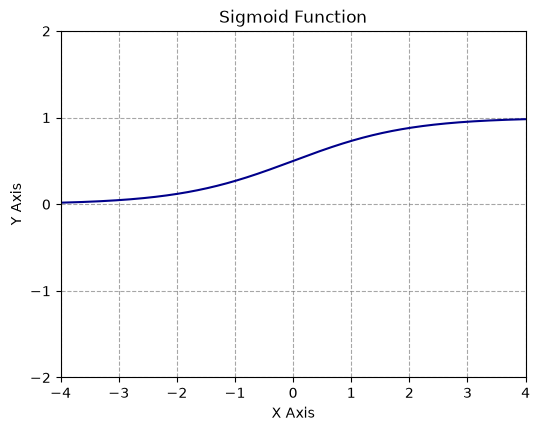

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)
y = 1 / (1 + np.exp(-x))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, y, color="darkblue", linewidth=1.5)

ax.set_xlim(-4, 4)
ax.set_ylim(-2, 2)
ax.set_xticks(range(-4, 5))
ax.set_yticks(range(-2, 3))
ax.grid(True, linestyle="--", color="gray", alpha=0.7)

ax.set_title("Sigmoid Function")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
plt.show()

## Tanh Function

$$
f(x) = \frac{2}{1 + e^{-2x}} - 1
$$

- used in hidden layers

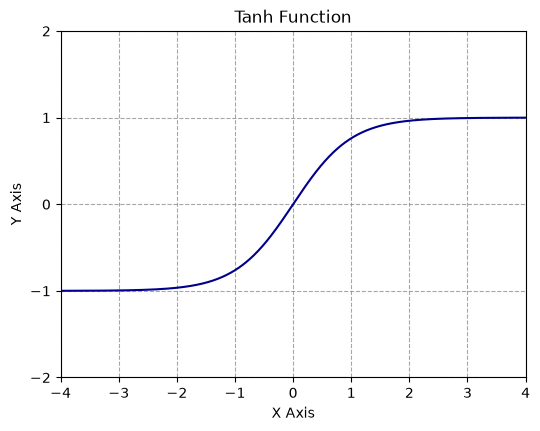

In [12]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)
y = np.tanh(x)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, y, color="darkblue", linewidth=1.5)

ax.set_xlim(-4, 4)
ax.set_ylim(-2, 2)
ax.set_xticks(range(-4, 5))
ax.set_yticks(range(-2, 3))
ax.grid(True, linestyle="--", color="gray", alpha=0.7)

ax.set_title("Tanh Function")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
plt.show()

## ReLU Function

$$
f(x) = \max(0, x)
$$

- most popular choice in most neural networks

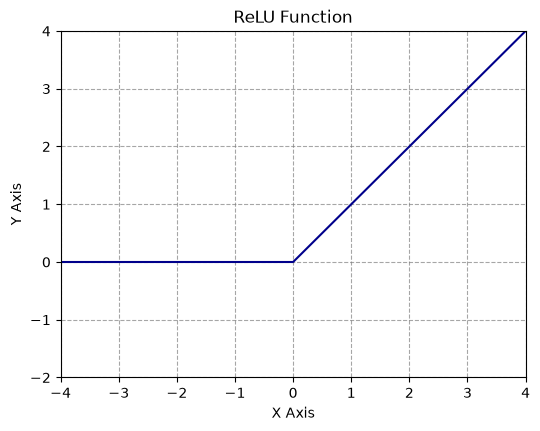

In [13]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)
y = np.maximum(0, x)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, y, color="darkblue", linewidth=1.5)

ax.set_xlim(-4, 4)
ax.set_ylim(-2, 4)
ax.set_xticks(range(-4, 5))
ax.set_yticks(range(-2, 5))
ax.grid(True, linestyle="--", color="gray", alpha=0.7)

ax.set_title("ReLU Function")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
plt.show()

## Leaky ReLU Function

$$
f(x) = 
\begin{cases}
x \quad &\text{if}\ x \geq 0 \\
\alpha \cdot x \quad &\text{otherwise}
\end{cases}
$$

- slightly modified and improved version of ReLU
- tries to solve the vanishing gradient problem
- $\alpha$ is typically a very small value (e.g., 0.2)

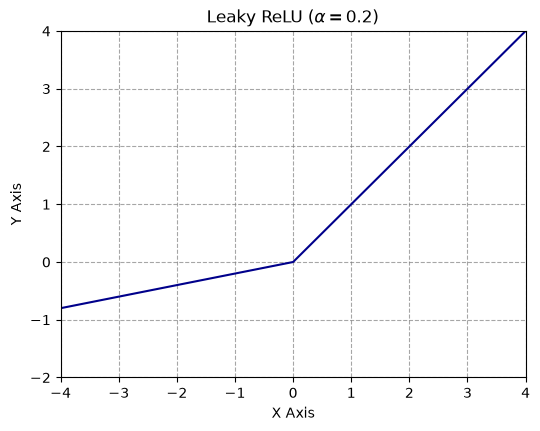

In [14]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 0.2
x = np.linspace(-4, 4, 1000)
y = np.where(x > 0, x, alpha * x)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, y, color="darkblue", linewidth=1.5)

ax.set_xlim(-4, 4)
ax.set_ylim(-2, 4)
ax.set_xticks(range(-4, 5))
ax.set_yticks(range(-2, 5))
ax.grid(True, linestyle="--", color="gray", alpha=0.7)

ax.set_title(r"Leaky ReLU ($\alpha = 0.2$)")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
plt.show()

## Softmax Function

$$
S(y_{i}) = \frac{e^{y_i}}{\sum e^{y_j}}
$$

- used in last layer of multi-class classification problem
- output probabilities for each class

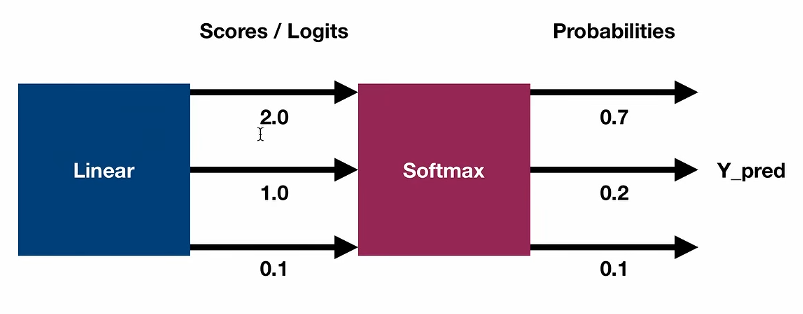

## Using Activation Functions in PyTorch

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F

### Option 1: Create `nn` modules

In [16]:
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(NeuralNet, self).__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.linear1(x)
        out = self.relu(out)
        out = self.linear2(out)
        out = self.sigmoid(out)
        return out

### Option 2: Use Activation Functions Directly in Forward Pass

In [19]:
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(NeuralNet, self).__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.linear2 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # activation functions in forward pass
        out = torch.relu(self.linear1(x))
        out = F.leaky_relu(self.linear2(out)) # leaky relu only available with this
        return out